## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

За тесты на функции из отдельных файлов ставится часть оценки за домашку. Напишите их для `json_dict_processing.py`, `dataset_helpers.py`, `aggregations.py` и `atribute_manager.py`. То же для функций в конфигах: `process_year`, процессор призов, процессоры лауреатов. Тестовые файлы создаются рядом с модулями, которые они тестируют.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутствовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
import requests
URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'


# Без headers не давал загрузить .json()
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
    'Accept': 'application/json'
}

laureates_response = requests.get(URL_LAUREATES, headers=headers)
laureates = laureates_response.json()

In [2]:
from configs.laureates_configs import process_orgs, process_persons
from processing.json_dict_processing import create_processor

# Простой тест обработчика
test_dict = {'a': {'b': '42'}}
test_cfg = {'val': (['a', 'b'], int)}
test_proc = create_processor(test_cfg, list_processor=False)
assert test_proc(test_dict) == {'val': 42}


def parse_laureate(item):
    if 'knownName' in item:
        res = process_persons(item)
        res['type_'] = 'person'
        return res
    if 'orgName' in item:
        res = process_orgs(item)
        res['type_'] = 'org'
        return res
    raise ValueError(f"Неизвестный тип лауреата: id={item.get('id')}")


laureates_data = [parse_laureate(item) for item in laureates['laureates']]

assert len(laureates_data) == len(laureates['laureates'])
assert all(row['type_'] in ('person', 'org') for row in laureates_data)
assert all(isinstance(row['prizes_relevant'], list) for row in laureates_data)

print(f'Лауреатов: {len(laureates_data)}')
print('Пример:', laureates_data[0])

Лауреатов: 1028
Пример: {'id': '745', 'name': 'A. Michael Spence', 'gender': 'male', 'birth_year': 1943, 'country_birth': 'USA', 'country_now': 'USA', 'prizes_relevant': [{'prize_amount': 10000000, 'prize_amount_adjusted': 15547541, 'award_year': 2001, 'category_en': 'Economic Sciences', 'prize_status': 'received'}], 'type_': 'person'}




### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
from collections import Counter

from analytics.aggregations import compute_count, count_by_value
from analytics.dataset_helpers import (
    compute_missing_ratios,
    count_missing_values,
    filter_dataset,
)

print('Всего записей:', compute_count(laureates_data))
print('По типам:', dict(count_by_value(laureates_data, 'type_')), '\n')

print('Пропуски (все):', count_missing_values(laureates_data))
print('Доля пропусков (все):', compute_missing_ratios(laureates_data))

persons = filter_dataset(laureates_data, {'type_': 'person'})
orgs = filter_dataset(laureates_data, {'type_': 'org'})

print('\nПропуски (люди):', count_missing_values(persons))
print('Доля пропусков (люди):', compute_missing_ratios(persons))
print('\nПропуски (организации):', count_missing_values(orgs))
print('Доля пропусков (организации):', compute_missing_ratios(orgs))


def check_ids(records):
    by_id = {int(row['id']): row for row in records}
    all_ids = [int(row['id']) for row in records]

    min_id, max_id = min(all_ids), max(all_ids)
    min_years = [p['award_year'] for p in by_id[min_id]['prizes_relevant']]
    max_years = [p['award_year'] for p in by_id[max_id]['prizes_relevant']]

    duplicates = [lid for lid, cnt in Counter(all_ids).items() if cnt > 1]
    sorted_ids = sorted(by_id)
    gaps = [
        (sorted_ids[i], sorted_ids[i + 1])
        for i in range(len(sorted_ids) - 1)
        if sorted_ids[i + 1] - sorted_ids[i] > 1
    ]

    print(f"\nmin id: {min_id} ({by_id[min_id]['name']}, {min_years})")
    print(f"max id: {max_id} ({by_id[max_id]['name']}, {max_years})")
    print('Дубликаты id:', duplicates)
    print(f'Разрывы > 1: {len(gaps)}, первые 10: {gaps[:10]}')


check_ids(laureates_data)

Всего записей: 1028
По типам: {'person': 1000, 'org': 28} 

Пропуски (все): {'id': 0, 'name': 0, 'gender': 28, 'birth_year': 28, 'country_birth': 31, 'country_now': 7, 'prizes_relevant': 0, 'type_': 0, 'founded_year': 1001, 'country_founded': 1004}
Доля пропусков (все): {'id': 0.0, 'name': 0.0, 'gender': 0.0272, 'birth_year': 0.0272, 'country_birth': 0.0302, 'country_now': 0.0068, 'prizes_relevant': 0.0, 'type_': 0.0, 'founded_year': 0.9737, 'country_founded': 0.9767}

Пропуски (люди): {'id': 0, 'name': 0, 'gender': 0, 'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков (люди): {'id': 0.0, 'name': 0.0, 'gender': 0.0, 'birth_year': 0.0, 'country_birth': 0.003, 'country_now': 0.003, 'prizes_relevant': 0.0, 'type_': 0.0}

Пропуски (организации): {'id': 0, 'name': 0, 'founded_year': 1, 'country_founded': 4, 'country_now': 4, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков (организации): {'id': 0.0, 'name': 0.0, 'founded_year': 0.0357, 'c


Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

---

## **Решение:**

Для удобства работы добавим новые аттрибуты с помощью `analytics.atribute_manager.add_attributes`:
- `num_prizes` - количество премий у лауреата;
- `first_award_year` - год получения первой премии;
- `first_award_decade` - десятилетие получения первой премии (например, `1970`);
- `first_category` - категория первой премии;
- `age_at_first_prize` - возраст человека-лауреата на момент первой премии;

Также сформируем плоскую таблицу (одна запись = одно награждение) (`prize_records`), чтобы корректно считать статистику по категориям и годам с учётом многократных лауреатов.

In [4]:
import matplotlib.pyplot as plt

from analytics.aggregations import (
    compute_max,
    compute_mean,
    compute_median,
    compute_min,
    get_top_n,
)
from analytics.atribute_manager import add_attributes
from analytics.dataset_helpers import apply_aggregation_to_groups, group_by_attributes


def get_sorted_prizes(record):
    prizes = record.get('prizes_relevant') or []
    return sorted(
        prizes,
        key=lambda prize: (
            prize['award_year'] if prize.get('award_year') is not None else 9999
        ),
    )


def get_first_year(record):
    prizes = get_sorted_prizes(record)
    return prizes[0]['award_year'] if prizes else None


def get_first_category(record):
    prizes = get_sorted_prizes(record)
    return prizes[0]['category_en'] if prizes else None


def get_age_at_first_prize(record):
    if record.get('type_') != 'person':
        return None
    birth_year = record.get('birth_year')
    first_year = record.get('first_award_year')
    if birth_year is None or first_year is None:
        return None
    return first_year - birth_year


enriched_laureates = add_attributes(
    laureates_data,
    {
        'num_prizes': lambda row: len(row['prizes_relevant']),
        'first_award_year': get_first_year,
        'first_award_decade': lambda row: (
            (row['first_award_year'] // 10) * 10 if row['first_award_year'] else None
        ),
        'first_category': get_first_category,
        'age_at_first_prize': get_age_at_first_prize,
    },
)

# Разворачиваем призы в плоский список для группировок по категориям
prize_records = []
for row in enriched_laureates:
    for prize in row['prizes_relevant']:
        year = prize.get('award_year')
        prize_records.append({
            'id': row['id'],
            'name': row['name'],
            'type_': row['type_'],
            'gender': row.get('gender'),
            'country_now': row.get('country_now'),
            'award_year': year,
            'decade': (year // 10) * 10 if year else None,
            'category_en': prize.get('category_en'),
            'prize_status': prize.get('prize_status'),
        })

print('Записей о награждениях:', len(prize_records))

Записей о награждениях: 1036


### **2.2**

1. Сравним средний и медианный возраст.
2. Посмотрим различия по категориям и выведем топ 5 самых молодых и самых возрастных лауреатов.
3. Построим динамику среднего и медианного возраста по десятилетиям, чтобы оценить, стареет ли Нобелевская премия со временем.

Средний возраст: 60.61, медиана: 61.00
Мин / макс: 17 / 97

Возраст по категориям:
  Physics: среднее = 57.79, медиана = 56.00
  Physiology or Medicine: среднее = 59.02, медиана = 58.00
  Chemistry: среднее = 59.43, медиана = 58.00
  Peace: среднее = 60.97, медиана = 62.00
  Literature: среднее = 65.04, медиана = 67.00
  Economic Sciences: среднее = 67.21, медиана = 67.00

Топ-5 самых молодых:
  Malala Yousafzai (Peace, 2014) - 17 лет
  Lawrence Bragg (Physics, 1915) - 25 лет
  Nadia Murad (Peace, 2018) - 25 лет
  Carl D. Anderson (Physics, 1936) - 31 лет
  Paul A.M. Dirac (Physics, 1933) - 31 лет

Топ-5 самых возрастных:
  John B. Goodenough (Chemistry, 2019) - 97 лет
  Arthur Ashkin (Physics, 2018) - 96 лет
  Henri B. Kagan (Chemistry, 2026) - 96 лет
  John J. Hopfield (Physics, 2024) - 91 лет
  Klaus Hasselmann (Physics, 2021) - 90 лет


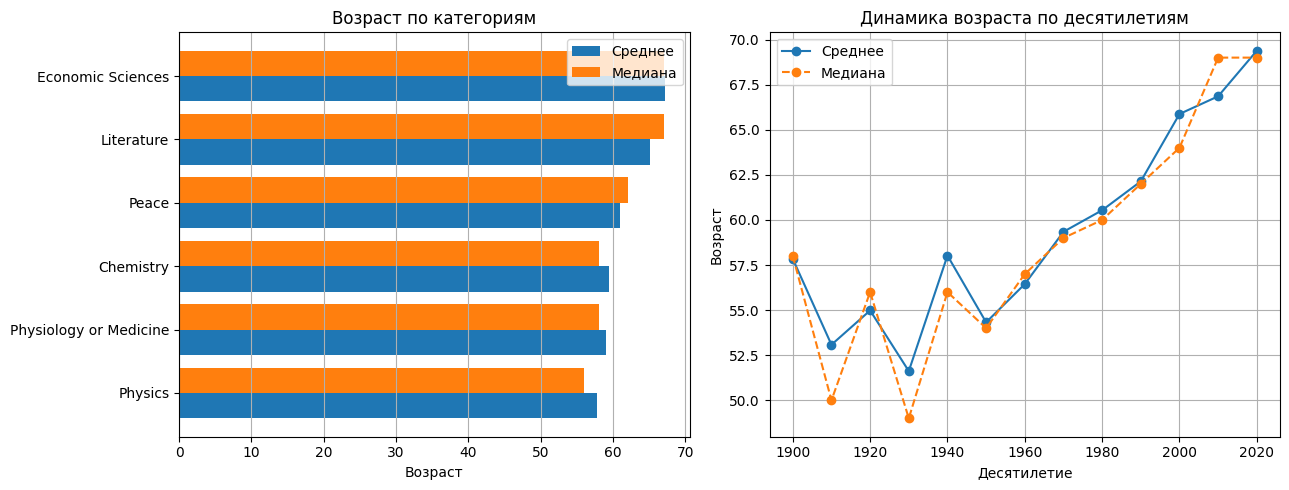

In [5]:
persons_with_age = filter_dataset(
    enriched_laureates,
    {'type_': 'person', 'age_at_first_prize': lambda age: age is not None}
)

mean_age = compute_mean(persons_with_age, 'age_at_first_prize')
median_age = compute_median(persons_with_age, 'age_at_first_prize')
min_age = compute_min(persons_with_age, 'age_at_first_prize')
max_age = compute_max(persons_with_age, 'age_at_first_prize')

print(f'Средний возраст: {mean_age:.2f}, медиана: {median_age:.2f}')
print(f'Мин / макс: {min_age:.0f} / {max_age:.0f}\n')

by_category = group_by_attributes(persons_with_age, ['first_category'])
mean_by_cat = apply_aggregation_to_groups(by_category, compute_mean, field='age_at_first_prize')
median_by_cat = apply_aggregation_to_groups(by_category, compute_median, field='age_at_first_prize')

print('Возраст по категориям:')
sorted_cats = sorted(mean_by_cat.items(), key=lambda item: item[1])
for (cat,), mean_val in sorted_cats:
    med_val = median_by_cat[(cat,)]
    print(f'  {cat}: среднее = {mean_val:.2f}, медиана = {med_val:.2f}')

print('\nТоп-5 самых молодых:')
for person in get_top_n(persons_with_age, 'age_at_first_prize', top_n=5, reverse=False):
    print(f"  {person['name']} ({person['first_category']}, {person['first_award_year']}) - {person['age_at_first_prize']} лет")

print('\nТоп-5 самых возрастных:')
for person in get_top_n(persons_with_age, 'age_at_first_prize', top_n=5, reverse=True):
    print(f"  {person['name']} ({person['first_category']}, {person['first_award_year']}) - {person['age_at_first_prize']} лет")

# Динамика по десятилетиям
by_decade = group_by_attributes(persons_with_age, ['first_award_decade'])
mean_by_decade = apply_aggregation_to_groups(by_decade, compute_mean, field='age_at_first_prize')
median_by_decade = apply_aggregation_to_groups(by_decade, compute_median, field='age_at_first_prize')

decades = sorted(key[0] for key in mean_by_decade if key[0] is not None)
mean_vals = [mean_by_decade[(d,)] for d in decades]
median_vals = [median_by_decade[(d,)] for d in decades]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cat_names = [key[0] for key, _ in sorted_cats]
cat_means = [mean_by_cat[(c,)] for c in cat_names]
cat_medians = [median_by_cat[(c,)] for c in cat_names]
y_pos = list(range(len(cat_names)))

ax1.barh([y - 0.2 for y in y_pos], cat_means, height=0.4, label='Среднее')
ax1.barh([y + 0.2 for y in y_pos], cat_medians, height=0.4, label='Медиана')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(cat_names)
ax1.set_xlabel('Возраст')
ax1.set_title('Возраст по категориям')
ax1.legend()
ax1.grid(axis='x')

ax2.plot(decades, mean_vals, marker='o', label='Среднее')
ax2.plot(decades, median_vals, marker='o', linestyle='--', label='Медиана')
ax2.set_xlabel('Десятилетие')
ax2.set_ylabel('Возраст')
ax2.set_title('Динамика возраста по десятилетиям')
ax2.legend()
ax2.grid(True)

fig.tight_layout()
plt.show()

### **2.3**

- определим общую долю женщин за всю историю премии;
- сравним распределение лауреаток по категориям суммарно и в последние два десятилетия (с 2005 года);
- визуализируем динамику числа женщин лауреатов по десятилетиям.

Награждений женщин: 70 из 1005 (6.97%)

По категориям (за все годы):
  Peace: 21
  Literature: 19
  Physiology or Medicine: 14
  Chemistry: 8
  Physics: 5
  Economic Sciences: 3

По категориям (до 1950 года):
  Literature: 5
  Peace: 3
  Chemistry: 2
  Physiology or Medicine: 1
  Physics: 1

По категориям (с 2005 года):
  Literature: 9
  Peace: 9
  Physiology or Medicine: 7
  Chemistry: 5
  Physics: 3
  Economic Sciences: 3


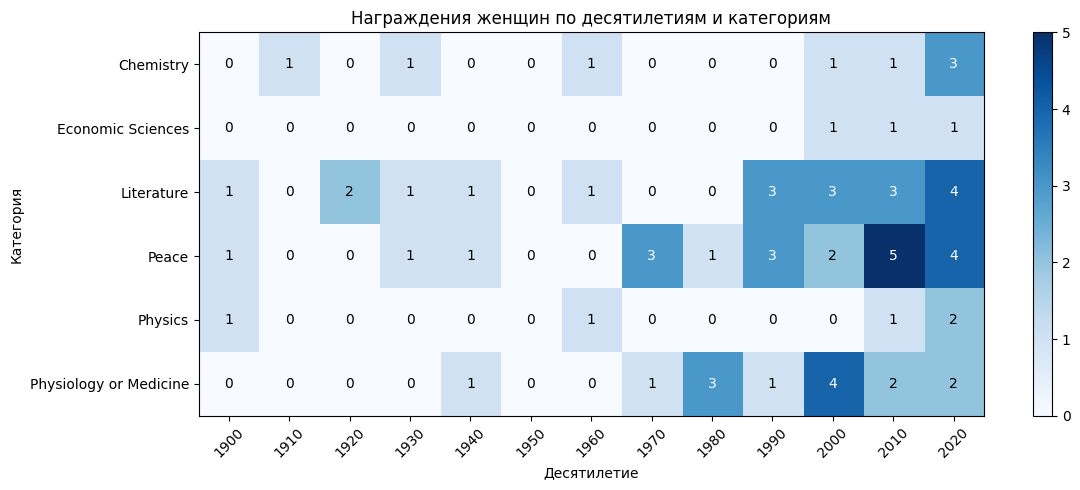

In [6]:
person_prizes = filter_dataset(prize_records, {'type_': 'person'})
female_prizes = filter_dataset(person_prizes, {'gender': 'female'})

total_person = compute_count(person_prizes)
total_female = compute_count(female_prizes)
female_share = total_female / total_person * 100
print(f'Награждений женщин: {total_female} из {total_person} ({female_share:.2f}%)\n')

print('По категориям (за все годы):')
for cat, cnt in count_by_value(female_prizes, 'category_en'):
    print(f'  {cat}: {cnt}')

early_female = filter_dataset(female_prizes, {'award_year': lambda y: y is not None and y <= 1950})
print('\nПо категориям (до 1950 года):')
for cat, cnt in count_by_value(early_female, 'category_en'):
    print(f'  {cat}: {cnt}')

recent_female = filter_dataset(female_prizes, {'award_year': lambda y: y is not None and y >= 2005})
print('\nПо категориям (с 2005 года):')
for cat, cnt in count_by_value(recent_female, 'category_en'):
    print(f'  {cat}: {cnt}')

# Тепловая карта по десятилетиям и категориям
decades = sorted({r['decade'] for r in person_prizes if r['decade'] is not None})
categories = sorted({r['category_en'] for r in person_prizes if r['category_en']})

grouped = group_by_attributes(female_prizes, ['decade', 'category_en'])
counts = apply_aggregation_to_groups(grouped, compute_count)

matrix = [[counts.get((dec, cat), 0) for dec in decades] for cat in categories]
threshold = max(counts.values()) / 2

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(matrix, cmap='Blues', aspect='auto')

ax.set_xticks(range(len(decades)))
ax.set_xticklabels([str(d) for d in decades], rotation=45)
ax.set_yticks(range(len(categories)))
ax.set_yticklabels(categories)

for i, row in enumerate(matrix):
    for j, val in enumerate(row):
        color = 'white' if val > threshold else 'black'
        ax.text(j, i, str(val), ha='center', va='center', color=color)

ax.set_title('Награждения женщин по десятилетиям и категориям')
ax.set_xlabel('Десятилетие')
ax.set_ylabel('Категория')
fig.colorbar(im, ax=ax)

fig.tight_layout()
plt.show()

### **2.4**

1. Сравним сырые исторические названия и проверим, всегда ли различие означает миграцию.
2. Добавим поле `'country_of_origin_adjusted_for_migration'` (современная страна места рождения/основания `country_now`), чтобы сравнение с современной страной принадлежности (`award_country_now`) отражало именно фактическую миграцию.
3. Выявим страны с наибольшей долей оттекших и притекших лауреатов (с порогом не менее 5 лауреатов) и визуализируем результаты.
4. Отдельно проверим, есть ли оттоки среди организаций.

Лауреатов с обеими странами: 757
Различаются сырые страны: 261
Из них не миграция (смена границ/названия): 21
Фактическая миграция: 244

Примеры расхождений без миграции:
  Aaron Ciechanover: British Protectorate of Palestine -> Israel (Israel)
  Ada E. Yonath: British Mandate of Palestine -> Israel (Israel)
  Adolf von Baeyer: Prussia -> Germany (Germany)
  Albert Szent-Györgyi: Austria-Hungary -> Hungary (Hungary)
  Albrecht Kossel: Mecklenburg -> Germany (Germany)

Топ стран по доле оттока (от 5 чел.):
  Poland: 100.0% (19 из 19)
  Scotland: 100.0% (9 из 9)
  China: 87.5% (7 из 8)
  India: 83.3% (5 из 6)
  Hungary: 80.0% (8 из 10)
  Canada: 78.9% (15 из 19)
  Australia: 66.7% (6 из 9)
  Austria: 66.7% (10 из 15)
  Italy: 61.5% (8 из 13)
  Russia: 55.0% (11 из 20)

Топ стран по доле притока (от 5 чел.):
  Canada: 60.0% (6 из 10)
  Switzerland: 50.0% (12 из 24)
  Israel: 40.0% (2 из 5)
  Australia: 40.0% (2 из 5)
  United Kingdom: 37.2% (35 из 94)
  Germany: 33.8% (25 из 74)
  USA: 33

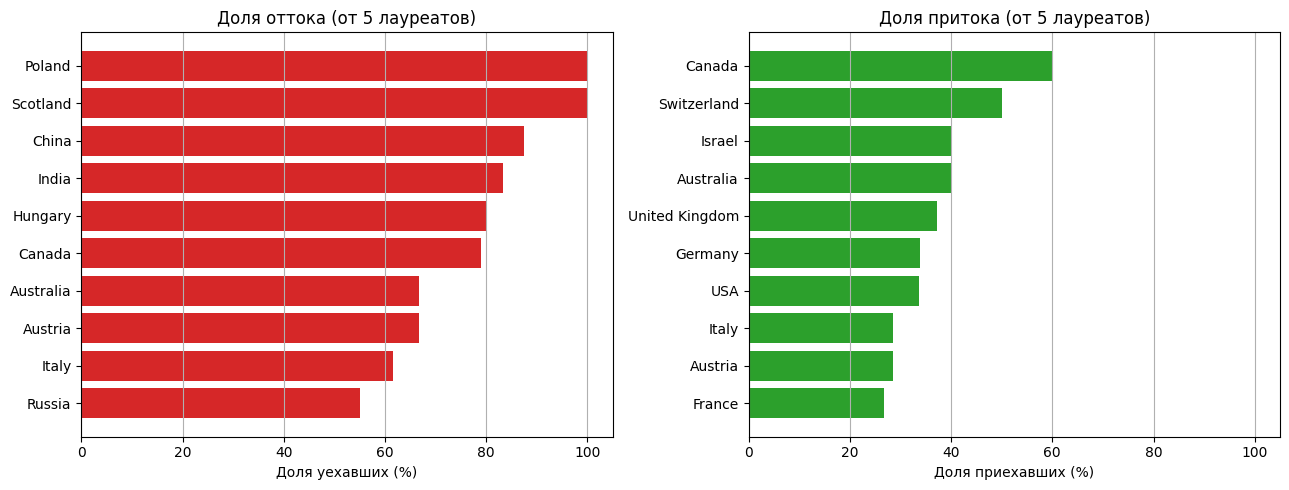


Организаций всего: 28
Организаций со страной при вручении: 0
Организаций со сменой названия страны основания: 0


In [7]:
from processing.json_dict_processing import extract_nested_value

# Достаём страну принадлежности на момент первой премии из исходного ответа API
award_countries = {}
for item in laureates['laureates']:
    prizes = sorted(
        item.get('nobelPrizes') or [],
        key=lambda p: int(p['awardYear']) if p.get('awardYear') else 9999,
    )
    country_raw = None
    country_now = None
    for prize in prizes:
        affiliations = prize.get('affiliations') or []
        if affiliations:
            country_raw = extract_nested_value(affiliations[0], ['country', 'en'])
            country_now = extract_nested_value(affiliations[0], ['countryNow', 'en'])
            break
    award_countries[item['id']] = (country_raw, country_now)

migration_data = add_attributes(
    enriched_laureates,
    {
        'country_origin_raw': lambda row: (
            row.get('country_birth') if row['type_'] == 'person' else row.get('country_founded')
        ),
        'award_country_raw': lambda row: award_countries.get(row['id'], (None, None))[0],
        'award_country_now': lambda row: award_countries.get(row['id'], (None, None))[1],
        'country_of_origin_adjusted_for_migration': lambda row: row.get('country_now'),
        'has_raw_diff': lambda row: row['country_origin_raw'] != row['award_country_raw'],
        'is_migrant': lambda row: row['country_of_origin_adjusted_for_migration'] != row['award_country_now'],
    },
)

comparable = filter_dataset(
    migration_data,
    {
        'country_origin_raw': lambda c: c is not None,
        'award_country_now': lambda c: c is not None,
    },
)
raw_diff = filter_dataset(comparable, {'has_raw_diff': True})
non_migration_diff = filter_dataset(comparable, {'has_raw_diff': True, 'is_migrant': False})
actual_migrants = filter_dataset(comparable, {'is_migrant': True})

print(f'Лауреатов с обеими странами: {compute_count(comparable)}')
print(f'Различаются сырые страны: {compute_count(raw_diff)}')
print(f'Из них не миграция (смена границ/названия): {compute_count(non_migration_diff)}')
print(f'Фактическая миграция: {compute_count(actual_migrants)}')

print('\nПримеры расхождений без миграции:')
for row in non_migration_diff[:5]:
    print(f"  {row['name']}: {row['country_origin_raw']} -> {row['award_country_raw']} ({row['country_of_origin_adjusted_for_migration']})")


def calc_migration_stats(grouped, compare_field, min_count):
    stats = []
    for (country,), records in grouped.items():
        total = compute_count(records)
        if total >= min_count:
            moved = compute_count(filter_dataset(records, {compare_field: lambda c: c != country}))
            stats.append({
                'country': country,
                'total': total,
                'moved': moved,
                'share': round(moved / total * 100, 1),
            })
    return stats


min_laureates = 5
by_origin = group_by_attributes(comparable, ['country_of_origin_adjusted_for_migration'])
by_award = group_by_attributes(comparable, ['award_country_now'])

top_outflow = get_top_n(calc_migration_stats(by_origin, 'award_country_now', min_laureates), 'share', top_n=10)
top_inflow = get_top_n(calc_migration_stats(by_award, 'country_of_origin_adjusted_for_migration', min_laureates), 'share', top_n=10)

print(f'\nТоп стран по доле оттока (от {min_laureates} чел.):')
for item in top_outflow:
    print(f"  {item['country']}: {item['share']}% ({item['moved']} из {item['total']})")

print(f'\nТоп стран по доле притока (от {min_laureates} чел.):')
for item in top_inflow:
    print(f"  {item['country']}: {item['share']}% ({item['moved']} из {item['total']})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.barh([x['country'] for x in top_outflow][::-1], [x['share'] for x in top_outflow][::-1], color='tab:red')
ax1.set_title(f'Доля оттока (от {min_laureates} лауреатов)')
ax1.set_xlabel('Доля уехавших (%)')
ax1.set_xlim(0, 105)
ax1.grid(axis='x')

ax2.barh([x['country'] for x in top_inflow][::-1], [x['share'] for x in top_inflow][::-1], color='tab:green')
ax2.set_title(f'Доля притока (от {min_laureates} лауреатов)')
ax2.set_xlabel('Доля приехавших (%)')
ax2.set_xlim(0, 105)
ax2.grid(axis='x')

fig.tight_layout()
plt.show()

# Проверка организаций
orgs_migration = filter_dataset(migration_data, {'type_': 'org'})
orgs_with_affil = filter_dataset(orgs_migration, {'award_country_now': lambda c: c is not None})
orgs_border_diff = [
    r for r in orgs_migration
    if r['country_origin_raw'] and r['country_now'] and r['country_origin_raw'] != r['country_now']
]

print(f'\nОрганизаций всего: {compute_count(orgs_migration)}')
print(f'Организаций со страной при вручении: {compute_count(orgs_with_affil)}')
print(f'Организаций со сменой названия страны основания: {compute_count(orgs_border_diff)}')
for org in orgs_border_diff:
    print(f"  {org['name']}: {org['country_origin_raw']} -> {org['country_now']}")

### **2.1, 2.5 и 2.6**

1. Выведем топ 5 стран (по современным границам `country_now`) в общем и в разрезе каждой категории.
2. Посчитаем, кто получил премию больше одного и больше двух раз, совпадают ли категории и какой средний интервал между первой и второй премией.
3. Посмотрим в каких категориях чаще всего отказывались от награды и были ли отказы среди организаций.

In [8]:
# Топ 5 стран всего и по категориям
top_countries = count_by_value(enriched_laureates, 'country_now', top_n=5)
print('Топ-5 стран по числу лауреатов:')
for country, cnt in top_countries:
    print(f'  {country}: {cnt}')

print('\nТоп-5 стран по категориям:')
prizes_by_cat = group_by_attributes(prize_records, ['category_en'])
top_by_cat = apply_aggregation_to_groups(prizes_by_cat, count_by_value, field='country_now', top_n=5)
for (cat,), countries in sorted(top_by_cat.items()):
    line = ', '.join(f'{c} ({n})' for c, n in countries)
    print(f'  {cat}: {line}')

# Многократные лауреаты
multi_laureates = filter_dataset(enriched_laureates, {'num_prizes': lambda n: n > 1})
more_than_two = filter_dataset(enriched_laureates, {'num_prizes': lambda n: n > 2})

print(f'\nПолучили больше одной премии ({compute_count(multi_laureates)}):')
gaps = []
same_cat = 0
for row in multi_laureates:
    prizes = get_sorted_prizes(row)
    years = [p['award_year'] for p in prizes]
    cats = [p['category_en'] for p in prizes]
    gaps.append({'gap': years[1] - years[0]})
    if cats[0] == cats[1]:
        same_cat += 1
    print(f"  {row['name']} ({row['type_']}) - {years}, {cats}")

print('\nБольше двух премий:', [r['name'] for r in more_than_two])
print(f'Категория совпала у {same_cat} из {compute_count(multi_laureates)}')
print(f"Средний разрыв между 1-й и 2-й премией: {compute_mean(gaps, 'gap'):.2f} лет")

# Отказы от премий
declined = filter_dataset(prize_records, {'prize_status': 'declined'})
declined_orgs = filter_dataset(declined, {'type_': 'org'})
print(f'\nВсего отказов: {compute_count(declined)}')
print('По категориям:', count_by_value(declined, 'category_en'))
print(f'Среди организаций: {compute_count(declined_orgs)}')

Топ-5 стран по числу лауреатов:
  USA: 306
  United Kingdom: 96
  Germany: 86
  France: 66
  Japan: 32

Топ-5 стран по категориям:
  Chemistry: USA (60), United Kingdom (27), Germany (26), France (12), Japan (9)
  Economic Sciences: USA (56), United Kingdom (7), Canada (5), France (5), the Netherlands (4)
  Literature: France (12), USA (10), Sweden (7), Poland (7), Germany (7)
  Peace: USA (26), France (12), Switzerland (11), United Kingdom (7), Russia (5)
  Physics: USA (72), Germany (27), United Kingdom (25), France (13), Japan (12)
  Physiology or Medicine: USA (85), United Kingdom (25), Germany (20), France (12), Sweden (8)

Получили больше одной премии (7):
  Frederick Sanger (person) - [1958, 1980], ['Chemistry', 'Chemistry']
  International Committee of the Red Cross (org) - [1917, 1944, 1963], ['Peace', 'Peace', 'Peace']
  John Bardeen (person) - [1956, 1972], ['Physics', 'Physics']
  K. Barry Sharpless (person) - [2001, 2022], ['Chemistry', 'Chemistry']
  Linus Pauling (person

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)

---

## **Решение:**


Пересоберём корпус текстов мотиваций, включив извлечение поля `motivation_en` через `person_processor(include_motivation=True)` и `org_processor(include_motivation=True)`:
- выделим топ 50 слов в сырых текстах;
- очистим корпус от общеанглийских стоп-слов из `configs/stopwords.py` и посмотрим обновлённый топ-20;
- сравним топ 10 слов по категориям по обычной частоте и по метрике TF-IDF (рассматривая тексты каждой из 6 категорий как отдельный документ).

In [9]:
import math
import re

from configs.laureates_configs import org_processor, person_processor
from configs.stopwords import ENGLISH_STOPWORDS

person_proc = person_processor(include_motivation=True)
org_proc = org_processor(include_motivation=True)


def tokenize(text):
    if not text:
        return []
    return re.findall(r'[a-z]{2,}', text.lower())


all_words = []
words_by_cat = {}

for item in laureates['laureates']:
    if 'knownName' in item:
        parsed = person_proc(item)
    elif 'orgName' in item:
        parsed = org_proc(item)
    else:
        continue

    for prize in parsed.get('prizes_relevant') or []:
        cat = prize.get('category_en')
        words = tokenize(prize.get('motivation_en'))
        all_words.extend(words)
        if cat:
            words_by_cat.setdefault(cat, []).extend(words)

top_50 = [w for w, _ in Counter(all_words).most_common(50)]
print('Топ 50 слов без очистки:')
print(top_50)

clean_words = [w for w in all_words if w not in ENGLISH_STOPWORDS]
print('\nТоп 20 после удаления стоп слов:')
print(Counter(clean_words).most_common(20))

clean_by_cat = {
    cat: [w for w in words if w not in ENGLISH_STOPWORDS]
    for cat, words in words_by_cat.items()
}

# Считаем TF-IDF, где каждый документ это тексты одной категории
n_docs = len(clean_by_cat)
df = Counter()
for words in clean_by_cat.values():
    df.update(set(words))

print('\nТоп 10 по категориям:')
for cat, words in sorted(clean_by_cat.items()):
    counts = Counter(words)
    total = len(words)
    top_freq = [w for w, _ in counts.most_common(10)]

    tfidf = {
        w: (cnt / total) * math.log((1 + n_docs) / (1 + df[w]))
        for w, cnt in counts.items()
    }
    top_tfidf = sorted(tfidf, key=tfidf.get, reverse=True)[:10]

    print(f'\n{cat}:')
    print(' частота:', top_freq)
    print(' TF-IDF:', top_tfidf)

Топ 50 слов без очистки:
['of', 'the', 'for', 'and', 'in', 'their', 'his', 'to', 'discovery', 'discoveries', 'concerning', 'development', 'work', 'on', 'with', 'which', 'by', 'theory', 'contributions', 'has', 'structure', 'that', 'peace', 'recognition', 'economic', 'human', 'chemical', 'as', 'analysis', 'new', 'its', 'synthesis', 'pioneering', 'an', 'fundamental', 'efforts', 'between', 'chemistry', 'he', 'her', 'studies', 'through', 'international', 'method', 'especially', 'methods', 'having', 'role', 'research', 'quantum']

Топ 20 после удаления стоп слов:
[('discovery', 211), ('discoveries', 172), ('concerning', 124), ('development', 110), ('work', 106), ('theory', 74), ('contributions', 61), ('structure', 58), ('peace', 53), ('recognition', 48), ('economic', 45), ('human', 44), ('chemical', 43), ('analysis', 42), ('new', 41), ('synthesis', 38), ('pioneering', 38), ('fundamental', 37), ('efforts', 36), ('chemistry', 34)]

Топ 10 по категориям:

Chemistry:
 частота: ['development', 'd

## Итоговые выводы

1. **Данные и парсинг.** В датасете 1028 лауреатов (1000 человек и 28 организаций). Пропуски в общей таблице в основном из-за того, что у людей и организаций разные поля (`birth_year`/`gender` против `founded_year`/`country_founded`). Если смотреть отдельно, пропусков почти нет: у людей 0.3% по стране рождения, у организаций 3.6% по году основания и 14.3% по стране. Дубликатов `id` нет, но в диапазоне от 1 до 1070 есть 24 разрыва в нумерации.

2. **Возраст.** Средний возраст при получении первой премии - 60.61 лет, медиана - 61 год (разброс от 17 до 97), так что сильного перекоса в распределении нет. Раньше всего обычно получают премию по физике (57.79) и медицине (59.02), позже всего по литературе (65.04) и экономике (67.21). По десятилетиям видно, что лауреаты со временем становятся старше.

3. **Гендер.** Женщин среди индивидуальных награждений 70 из 1005 (6.97%). До 1950 года больше всего лауреаток было в литературе (5) и премии мира (3). С 2005 года их стало заметно больше: лидируют те же литература и мир (по 9), но подтянулись медицина (7) и химия (5).

4. **Миграции.** Из 757 лауреатов с известными странами рождения и принадлежности сырые названия не совпадают у 261, но 21 случай - это просто смена границ или переименования (`Prussia -> Germany`, `Austria-Hungary -> Hungary` и т.п.). После корректировки через `country_of_origin_adjusted_for_migration` остается 244 реальных мигранта. Среди стран от 5 лауреатов самый большой процент оттока у Польши (100%), Шотландии (100%), Китая (87.5%), Индии (83.3%) и Венгрии (80.0%). По доле притока впереди Канада (60.0%), Швейцария (50.0%), Израиль и Австралия (по 40.0%) и Великобритания (37.2%). У организаций оттоков не нашлось.

5. **Страны, многократные лауреаты и отказы.** По общему числу лауреатов США лидирует (306 человек и 1-е место во всех категориях, кроме литературы, где первая Франция). Больше одной премии получили 7 лауреатов, а больше двух - только *International Committee of the Red Cross* (3 раза). У 5 из 7 категории первых двух премий совпали, средний разрыв между ними - 18.43 года. Отказов всего 2 (по одному в литературе и премии мира), среди организаций их не было.

6. **Тексты мотиваций.** В сыром топ-50 преобладают обычные английские предлоги и артикли (`of`, `the`, `for`, `and`, `in`, `their`, `his`, `to`, `on`, `with`, `by`), но бывают и осмысленные слова (`discovery`, `development`, `theory`, `peace`, `economic`, `chemical`, `synthesis`, `chemistry`, `quantum`). После удаления стоп слов в топе остались общие научные слова вроде `discovery`, `discoveries`, `concerning`, `development`, `work`, `theory`, `contributions`. Из-за этого обычный подсчет частоты по категориям дает много пересечений, а TF-IDF их приглушает и вытягивает подходящие по контексту слова: в химии это `organic`, `synthesis`, `protein`, `molecules`, в экономике - `markets`, `financial`, `macroeconomic`, `policy`, в литературе - `poetry`, `narrative`, `epic`, `writing`, в премии мира - `war`, `peaceful`, `rights`, `democracy`, в физике - `particles`, `quantum`, `atomic`, `laser`, в медицине - `genetic`, `cells`, `viruses`, `nerve`.